# Análise Exploratória — Focos de Calor no Brasil (2012–2021)

**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) — 6º período, Bacharelado em Sistemas de Informação

**Alunos:** Rodrigo Leon de Andrade Silva

Notebook de exploração, prototipação e validação. Toda a lógica reutilizável está em `src/etl.py` (limpeza) e `src/analysis.py` (métricas e figuras); aqui ela é chamada e inspecionada passo a passo.

**Perguntas de pesquisa**
- **RQ1** — Como os focos se distribuem no tempo (tendência interanual e sazonalidade) e quais anos se destacam como anômalos?
- **RQ2** — Quais biomas, estados e municípios concentram os focos, e quão desigual é essa concentração?
- **RQ3** — Em que medida as variáveis meteorológicas do INPE (risco de fogo, dias sem chuva, precipitação) se associam à frequência e à intensidade (FRP) dos focos?

In [ ]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import etl, analysis as an

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 1. Ingestão dos dados brutos
Os 10 arquivos anuais (`Focos_AAAA-01-01_AAAA-12-31.csv`) são lidos com tipagem explícita; `NA` é tratado como ausente.

In [ ]:
raw = etl.extract()
print(raw.shape)
raw.head()

(1867181, 13)


,datahora,satelite,pais,estado,municipio,bioma,diasemchuva,precipitacao,riscofogo,latitude,longitude,frp,arquivo_origem
0,2012/08/24 16:41:00,AQUA_M-T,Brasil,MARANHAO,TUNTUM,Cerrado,NaN,NaN,NaN,-5.615,-44.757,NaN,Focos_2012-01-01_2012-12-31.csv
1,2012/08/24 16:41:00,AQUA_M-T,Brasil,MARANHAO,TUNTUM,Cerrado,NaN,NaN,NaN,-5.617,-44.893,NaN,Focos_2012-01-01_2012-12-31.csv
2,2012/08/26 16:28:00,AQUA_M-T,Brasil,MARANHAO,BALSAS,Cerrado,NaN,NaN,NaN,-8.462,-46.211,NaN,Focos_2012-01-01_2012-12-31.csv
3,2012/08/27 17:11:00,AQUA_M-T,Brasil,PARA,ALTAMIRA,Amazonia,NaN,NaN,NaN,-8.181,-54.880,NaN,Focos_2012-01-01_2012-12-31.csv
4,2012/08/29 16:57:00,AQUA_M-T,Brasil,TOCANTINS,ALMAS,Cerrado,NaN,NaN,NaN,-11.668,-47.184,NaN,Focos_2012-01-01_2012-12-31.csv


In [ ]:
# Perfil de ausência e sentinelas antes da limpeza
perfil = pd.DataFrame({
    "nulos_%": raw.isna().mean() * 100,
    "sentinela_-999": (raw.select_dtypes("number") == -999).sum(),
}).fillna(0)
perfil

,nulos_%,sentinela_-999
arquivo_origem,0.000,0.000
bioma,0.000,0.000
datahora,0.000,0.000
diasemchuva,18.769,"10,611.000"
estado,0.000,0.000
frp,60.649,0.000
latitude,0.000,0.000
longitude,0.000,0.000
municipio,0.000,0.000
pais,0.000,0.000


In [ ]:
# Ausência das variáveis meteorológicas e do FRP por ano: é estrutural, não aleatória
raw.assign(ano=raw["datahora"].str[:4]).groupby("ano")[["riscofogo", "frp"]].apply(lambda x: x.notna().mean()).round(3)

,riscofogo,frp
ano,,
2012,0.000,0.000
2013,0.000,0.000
2014,1.000,0.000
2015,1.000,0.000
2016,1.000,0.000
2017,1.000,0.000
2018,1.000,1.000
2019,1.000,1.000
2020,0.977,0.988


Observações:
- `diasemchuva`, `precipitacao` e `riscofogo` não existem em 2012–2013 (e faltam em ~2% de 2020).
- `frp` (Fire Radiative Power) só passa a ser publicado a partir de 2018.
- `-999` é o código do INPE para valor não calculado e precisa virar `NaN` (do contrário, distorce médias: a média bruta de `riscofogo` é negativa!).

Por isso **não imputamos** essas variáveis: a ausência é por desenho da fonte. As análises da RQ3 usam apenas os anos com cobertura.

## 2. Transformação e persistência

In [ ]:
clean, report = etl.transform(raw)
report

{'linhas_brutas': 1867181, 'datas_invalidas': 0, 'bioma_nao_mapeado': 0, 'sentinelas_-999': {'diasemchuva': 10611, 'precipitacao': 0, 'riscofogo': 8130, 'frp': 0}, 'riscofogo_fora_0_1': 0, 'frp_negativo': 0, 'diasemchuva_maior_365': 693, 'coordenadas_fora_brasil_removidas': 0, 'duplicatas_removidas': 2, 'linhas_sem_data_removidas': 0, 'uf_nao_mapeada': 0, 'linhas_finais': 1867179, 'percentual_nulos_final': {'diasemchuva': 0.1934, 'precipitacao': 0.1877, 'riscofogo': 0.192, 'classe_risco': 0.192, 'frp': 0.6065}}

In [ ]:
etl.load(clean, report)
df = etl.load_processed()
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1867179 entries, 0 to 1867178
Data columns (total 24 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   datahora_utc              datetime64[us, UTC]
 1   data                      string             
 2   ano                       int64              
 3   mes                       int64              
 4   ano_mes                   string             
 5   dia_ano                   int64              
 6   estacao_seca              bool               
 7   satelite                  category           
 8   pais                      category           
 9   regiao                    category           
 10  estado                    category           
 11  uf                        category           
 12  municipio                 string             
 13  bioma                     category           
 14  latitude                  float64            
 15  longitude                 

## 3. RQ1 — Dinâmica temporal

In [ ]:
anual = df.groupby("ano").size().rename("focos").to_frame()
anual["var_%"] = anual["focos"].pct_change() * 100
anual

,focos,var_%
ano,,
2012,217238,NaN
2013,128149,-41.010
2014,175900,37.262
2015,216782,23.242
2016,184218,-15.022
2017,207511,12.644
2018,132870,-35.970
2019,197632,48.741
2020,222798,12.734


In [ ]:
an.tendencia_anual(df)

{'media': 186717.9, 'cv': 0.17984496115981444, 'ano_max': 2020, 'max': 222798, 'ano_min': 2013, 'min': 128149, 'kendall_tau': 0.06666666666666667, 'kendall_p': 0.8618005952380953, 'slope_ano': 1480.8909090909094, 'slope_p': 0.7130776580817209}

In [ ]:
mm = an.matriz_ano_mes(df)
(mm.sum() / mm.values.sum() * 100).round(1).rename(index=dict(enumerate(an.MESES, 1)))

mes
Jan    1.800
Fev    1.100
Mar    1.500
Abr    1.300
Mai    1.800
Jun    3.300
Jul    7.400
Ago   21.700
Set   28.500
Out   17.400
Nov    9.200
Dez    5.000
dtype: float64

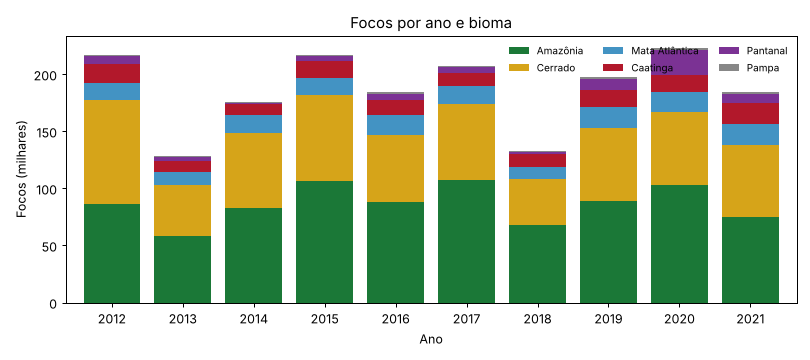

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
t = an.anual_por_bioma(df)
t.div(1000).plot(kind="bar", stacked=True, ax=ax, color=[an.BIOMA_COR[b] for b in t.columns], width=0.8)
ax.set(ylabel="Focos (milhares)", xlabel="Ano", title="Focos por ano e bioma")
ax.legend(ncol=3, frameon=False, fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [ ]:
an.indice_anomalia_bioma(df).round(2)

bioma,Amazônia,Cerrado,Mata Atlântica,Caatinga,Pantanal,Pampa
ano,,,,,,
2012,1.000,1.440,0.940,1.240,1.070,0.990
2013,0.680,0.700,0.730,0.730,0.490,0.750
2014,0.950,1.040,1.010,0.710,0.220,0.660
2015,1.230,1.190,0.960,1.120,0.640,0.680
2016,1.010,0.930,1.130,1.010,0.740,1.250
2017,1.240,1.060,1.000,0.820,0.830,0.880
2018,0.790,0.630,0.730,0.840,0.240,0.700
2019,1.030,1.010,1.170,1.110,1.430,1.330
2020,1.190,1.010,1.130,1.080,3.160,1.580


## 4. RQ2 — Concentração espacial

In [ ]:
pd.DataFrame({"focos": df.bioma.value_counts(), "%": df.bioma.value_counts(normalize=True) * 100})

,focos,%
bioma,,
Amazônia,865369,46.346
Cerrado,631047,33.797
Mata Atlântica,155660,8.337
Caatinga,134530,7.205
Pantanal,69915,3.744
Pampa,10658,0.571


In [ ]:
uf = df.uf.value_counts()
pd.DataFrame({"focos": uf, "% acumulado": uf.cumsum() / uf.sum() * 100}).head(10)

,focos,% acumulado
uf,,
PA,333174,17.844
MT,276848,32.671
MA,217537,44.321
TO,132684,51.427
AM,116609,57.673
PI,102417,63.158
RO,98819,68.450
BA,95189,73.548
MG,86660,78.189


In [ ]:
c = an.concentracao_municipios(df)
print(f"Municípios com ao menos 1 foco: {c['n_municipios']}")
print(f"Municípios necessários p/ 50% dos focos: {c['mun_50pct']}")
print(f"Participação do 1% de municípios com mais focos: {c['share_top1pct']:.1%}")
print(f"Índice de Gini (municípios): {c['gini']:.3f}")
c["top15"]

Municípios com ao menos 1 foco: 5434
Municípios necessários p/ 50% dos focos: 161
Participação do 1% de municípios com mais focos: 29.1%
Índice de Gini (municípios): 0.830


,uf,municipio,focos,rotulo
0,MS,CORUMBA,37038,Corumba (MS)
1,PA,SAO FELIX DO XINGU,31656,Sao Felix do Xingu (PA)
2,RO,PORTO VELHO,29760,Porto Velho (RO)
3,PA,ALTAMIRA,29341,Altamira (PA)
4,AM,LABREA,17948,Labrea (AM)
5,PA,NOVO PROGRESSO,17331,Novo Progresso (PA)
6,MT,COLNIZA,16605,Colniza (MT)
7,AM,APUI,14677,Apui (AM)
8,PA,ITAITUBA,12246,Itaituba (PA)
9,MA,MIRADOR,12000,Mirador (MA)


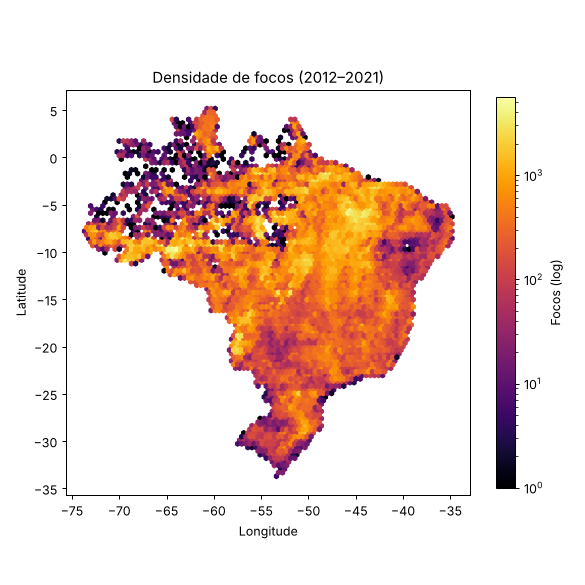

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
hb = ax.hexbin(df.longitude, df.latitude, gridsize=90, bins="log", cmap="inferno", mincnt=1)
ax.set_aspect("equal"); ax.set(title="Densidade de focos (2012–2021)", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(hb, ax=ax, shrink=0.7, label="Focos (log)"); plt.tight_layout(); plt.show()

## 5. RQ3 — Meteorologia × frequência e intensidade

In [ ]:
m = df[df.ano >= 2014]
m["classe_risco"].value_counts(normalize=True).reindex(an.RISCO_ORDEM).mul(100).round(1)

classe_risco
Mínimo    11.300
Baixo     10.800
Médio     11.200
Alto      11.800
Crítico   55.000
Name: proportion, dtype: float64

In [ ]:
mv = an.meteo_vs_frp(df)
print("n (2018–2021, meteorologia + FRP válidos):", mv["n"])
pd.DataFrame(mv["spearman"]).T

n (2018–2021, meteorologia + FRP válidos): 720653


,rho,p
riscofogo,0.222,0.000
diasemchuva,0.191,0.000
precipitacao,-0.124,0.000


In [ ]:
mv['box'].round(1)

,classe,n,q1,mediana,q3,lower,upper,p99,media
0,Mínimo,98983,11.500,19.400,37.500,0.000,76.500,311.900,37.800
1,Baixo,88776,12.600,22.600,45.800,0.000,95.700,410.200,46.800
2,Médio,85859,13.500,24.900,51.800,0.000,109.200,511.500,55.200
3,Alto,89999,15.100,28.500,61.100,0.000,130.100,690.900,68.100
4,Crítico,357036,18.600,35.300,73.200,0.000,155.100,664.800,75.400


In [ ]:
print(f"Limite de outlier (Q3 + 1,5·IQR): {mv['frp_outlier_lim']:.1f} MW")
print(f"Focos acima do limite: {mv['frp_outlier_share']:.1%}")
print(f"Energia (soma de FRP) concentrada no 1% mais intenso: {mv['frp_top1_energy_share']:.1%}")
mv["frp_mediana_bioma"]

Limite de outlier (Q3 + 1,5·IQR): 127.6 MW
Focos acima do limite: 10.2%
Energia (soma de FRP) concentrada no 1% mais intenso: 16.9%


bioma
Amazônia         27.100
Cerrado          31.800
Mata Atlântica   17.800
Caatinga         32.550
Pantanal         45.000
Pampa            12.800
Name: frp, dtype: float64

               rho     p
risco_medio  0.676 0.000
dsc_mediana  0.486 0.000
prec_media  -0.467 0.000


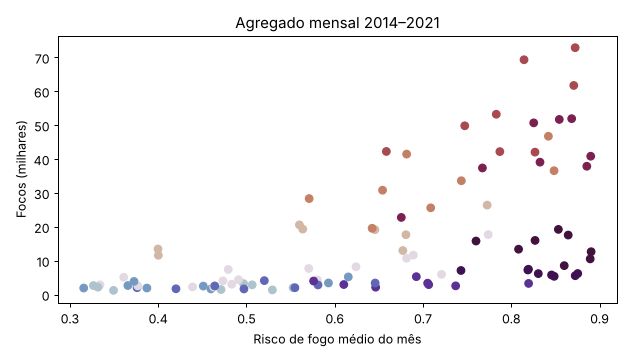

In [ ]:
g, rho = an.meteo_mensal(df)
print(pd.DataFrame(rho).T)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(g.risco_medio, g.focos / 1000, c=g.mes, cmap="twilight")
ax.set(xlabel="Risco de fogo médio do mês", ylabel="Focos (milhares)", title="Agregado mensal 2014–2021")
plt.tight_layout(); plt.show()

## 6. Exportação para o artigo
Gera as figuras estáticas (`docs/assets/*.png`) e o payload dos gráficos interativos Plotly (`docs/assets/figures.json`).

In [ ]:
paths = an.salvar_figuras_estaticas(df)
payload = an.exportar_json_plotly(df)
[p.name for p in paths]

['fig1_anual_bioma.png', 'fig2_heatmap_ano_mes.png', 'fig3_mapa_densidade.png', 'fig4_concentracao_municipios.png', 'fig5_anomalia_bioma.png', 'fig6_frp_risco.png', 'fig7_risco_mensal.png']